# 01 — Business & Data Understanding
**Ferngill & Co. | LUBS5308M practice assessment | CRISP-DM phases 1–2**

This notebook (a) frames the business problem and (b) checks and explores the raw customer file.
It **does not change the data** — all fixes happen in `02_data_preparation.ipynb`.

| Part | What we do |
|---|---|
| 1 | Business understanding (CRISP-DM phase 1) |
| 2 | First look at the data |
| 3 | Data-quality checks (missing values, odd values, consistency) |
| 4 | How concentrated is customer value? |
| 5 | What differs between high-value customers and the rest? |
| 6 | Which drivers overlap with each other? |
| 7 | Save the data-quality log |

**Outputs:** `outputs/tables/01_*.csv` and `outputs/figures/01_*.png`

## 1. Business Understanding (CRISP-DM phase 1)

| Element | Ferngill & Co. |
|---|---|
| **Business problem** | Campaigns treat all customers the same; personalised marketing is needed to spend effort efficiently. |
| **Decision owner** | Marketing director |
| **Business question** | *What distinguishes our most valuable customers, and how should marketing act on it?* |
| **Analytics question** | Which customer characteristics are linked to being in the high-value group (12-month spend)? |
| **Target** | `customer_value_12m` → turned into a *high-value* flag (top 20%, tested below) |
| **Success criterion** | A few **actionable** levers (subscription, email, channel, discounting, product range) with a clear link to value. |
| **Constraint** | 250 customers, one snapshot in time → we can show *association*, not prove *cause and effect*. |

## Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import os

# File locations (relative to this notebook, which lives in the 'notebooks' folder)
RAW_FILE   = "../dataset/ferngill_customers.csv"
FIG_FOLDER = "../outputs/figures/"
TAB_FOLDER = "../outputs/tables/"
os.makedirs(FIG_FOLDER, exist_ok=True)
os.makedirs(TAB_FOLDER, exist_ok=True)

# Chart colours (colour-blind safe): blue = high-value / main, orange = the rest
BLUE = "#2a78d6"
ORANGE = "#eb6834"
GREY = "#52514e"

## 2. First look at the data

In [2]:
df = pd.read_csv(RAW_FILE)

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
df.head()

Rows: 250
Columns: 13


,customer_id,age,region,acquisition_channel,tenure_months,total_orders,average_order_value,distinct_product_types,discount_sensitivity,email_engagement,satisfaction_rating,subscription_status,customer_value_12m
0,FG0001,32,Midlands,Marketplace,6,13,24.00,4,0.413,0.0,4.7,no,242.68
1,FG0002,33,Scotland & Wales,Instagram,48,26,56.96,8,0.164,70.2,4.8,yes,1833.39
2,FG0003,53,North,Google,3,5,31.35,3,0.051,33.1,4.5,no,169.39
3,FG0004,37,Scotland & Wales,Google,38,3,53.40,2,0.018,14.6,5.0,no,157.58
4,FG0005,36,Scotland & Wales,Google,16,7,19.94,4,0.214,50.6,5.0,no,114.05


In [3]:
# Column types and how many values are filled in
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   customer_id             250 non-null    object 
 1   age                     250 non-null    int64  
 2   region                  250 non-null    object 
 3   acquisition_channel     250 non-null    object 
 4   tenure_months           250 non-null    int64  
 5   total_orders            250 non-null    int64  
 6   average_order_value     250 non-null    float64
 7   distinct_product_types  250 non-null    int64  
 8   discount_sensitivity    250 non-null    float64
 9   email_engagement        244 non-null    float64
 10  satisfaction_rating     242 non-null    float64
 11  subscription_status     250 non-null    object 
 12  customer_value_12m      250 non-null    float64
dtypes: float64(5), int64(4), object(4)
memory usage: 25.5+ KB


In [4]:
# Summary statistics for the number columns
df.describe().round(2)

,age,tenure_months,total_orders,average_order_value,distinct_product_types,discount_sensitivity,email_engagement,satisfaction_rating,customer_value_12m
count,250.00,250.00,250.00,250.00,250.00,250.00,244.00,242.00,250.00
mean,39.58,24.83,11.02,32.65,4.50,0.16,53.08,4.16,353.47
std,13.01,14.70,7.02,16.38,2.16,0.12,23.68,0.74,308.89
min,18.00,1.00,1.00,5.00,1.00,0.00,0.00,1.70,4.44
25%,29.00,14.00,5.00,19.96,3.00,0.07,33.25,3.72,151.11
50%,38.00,23.00,10.00,28.94,4.00,0.13,51.40,4.40,228.91
75%,48.00,36.00,16.00,42.74,6.00,0.24,72.70,4.70,448.74
max,80.00,71.00,29.00,94.99,12.00,0.57,100.00,5.00,1833.39


In [5]:
# The text (category) columns
print(df["region"].value_counts(), "\n")
print(df["acquisition_channel"].value_counts(), "\n")
print(df["subscription_status"].value_counts())

region
Scotland & Wales    67
North               57
South West          46
South East          43
Midlands            37
Name: count, dtype: int64 

acquisition_channel
Instagram      79
Google         76
Marketplace    59
Referral       36
Name: count, dtype: int64 

subscription_status
no     159
yes     91
Name: count, dtype: int64


In [6]:
# Any duplicates?
print("Duplicate customer IDs:", df["customer_id"].duplicated().sum())
print("Fully duplicated rows: ", df.duplicated().sum())

Duplicate customer IDs: 0
Fully duplicated rows:  0


## 3. Data-quality checks
We record every issue we find in a simple list. At the end it is saved as a table, which becomes the to-do list for Step 2.

In [7]:
dq_log = []   # each item: [issue, column, rows affected, evidence, proposed treatment]

### 3.1 Are all values within the ranges described in the brief?
The brief says: discount sensitivity is 0–1, email engagement 0–100, satisfaction 1–5. Spend, orders and tenure cannot be negative.

In [8]:
print("Discount sensitivity outside 0-1:  ", ((df["discount_sensitivity"] < 0) | (df["discount_sensitivity"] > 1)).sum())
print("Email engagement outside 0-100:    ", ((df["email_engagement"] < 0) | (df["email_engagement"] > 100)).sum())
print("Satisfaction outside 1-5:          ", ((df["satisfaction_rating"] < 1) | (df["satisfaction_rating"] > 5)).sum())
print("Negative spend:                    ", (df["customer_value_12m"] < 0).sum())
print("Negative orders:                   ", (df["total_orders"] < 0).sum())
print("Negative tenure:                   ", (df["tenure_months"] < 0).sum())
print("Age under 18:                      ", (df["age"] < 18).sum())

Discount sensitivity outside 0-1:   0
Email engagement outside 0-100:     0
Satisfaction outside 1-5:           0
Negative spend:                     0
Negative orders:                    0
Negative tenure:                    0
Age under 18:                       0


Everything is within range. No impossible values.

### 3.2 Missing values — how many, and *who* is missing?

In [9]:
print(df.isnull().sum())

customer_id               0
age                       0
region                    0
acquisition_channel       0
tenure_months             0
total_orders              0
average_order_value       0
distinct_product_types    0
discount_sensitivity      0
email_engagement          6
satisfaction_rating       8
subscription_status       0
customer_value_12m        0
dtype: int64


Only two columns have gaps. The important question is **whether the gaps are random**.
If missing values are concentrated in one type of customer, a simple fix could bias the results.
We compare the share of **subscribers** among customers with a missing value vs everyone else.

In [10]:
# Satisfaction rating
sat_missing = df["satisfaction_rating"].isnull()

print("Customers with missing satisfaction:", sat_missing.sum())
print("Subscriber share among them:   ", round((df.loc[sat_missing, "subscription_status"] == "yes").mean() * 100), "%")
print("Subscriber share among the rest:", round((df.loc[~sat_missing, "subscription_status"] == "yes").mean() * 100), "%")

# Fisher's exact test: is missingness linked to subscription? (good for small numbers)
table = pd.crosstab(sat_missing, df["subscription_status"])
print("\n", table)
odds_ratio, p_value = stats.fisher_exact(table)
print("\nFisher's exact test p-value:", round(p_value, 3))

Customers with missing satisfaction: 8
Subscriber share among them:    75 %
Subscriber share among the rest: 35 %

 subscription_status   no  yes
satisfaction_rating          
False                157   85
True                   2    6

Fisher's exact test p-value: 0.029


In [11]:
df.loc[sat_missing, ["customer_id", "subscription_status", "acquisition_channel", "customer_value_12m"]]

,customer_id,subscription_status,acquisition_channel,customer_value_12m
62,FG0063,no,Marketplace,119.00
92,FG0093,yes,Instagram,738.50
116,FG0117,yes,Google,443.54
122,FG0123,yes,Referral,724.49
185,FG0186,yes,Instagram,420.89
198,FG0199,no,Google,67.17
200,FG0201,yes,Instagram,441.98
242,FG0243,yes,Google,687.99


In [12]:
# Email engagement - same check
email_missing = df["email_engagement"].isnull()

print("Customers with missing email engagement:", email_missing.sum())
print("Subscriber share among them:   ", round((df.loc[email_missing, "subscription_status"] == "yes").mean() * 100), "%")
print("Subscriber share among the rest:", round((df.loc[~email_missing, "subscription_status"] == "yes").mean() * 100), "%")

table = pd.crosstab(email_missing, df["subscription_status"])
odds_ratio, p_value = stats.fisher_exact(table)
print("\nFisher's exact test p-value:", round(p_value, 3))

Customers with missing email engagement: 6
Subscriber share among them:    50 %
Subscriber share among the rest: 36 %

Fisher's exact test p-value: 0.671


In [13]:
df.loc[email_missing, ["customer_id", "subscription_status", "acquisition_channel", "customer_value_12m"]]

,customer_id,subscription_status,acquisition_channel,customer_value_12m
25,FG0026,no,Instagram,261.25
64,FG0065,yes,Google,907.00
123,FG0124,no,Instagram,50.30
154,FG0155,yes,Google,753.40
156,FG0157,no,Marketplace,267.00
199,FG0200,yes,Google,439.04


**Finding:** missing satisfaction ratings are **not random** — 75% belong to subscribers vs 35% of everyone else (p ≈ 0.03).
Missing email scores show no clear pattern. Both will be filled using the customer's *own subscription group* in Step 2.

In [14]:
dq_log.append(["Missing values", "email_engagement", email_missing.sum(),
               "6/250 (2.4%); no clear pattern by subscription",
               "Fill with subscription-group median + flag"])
dq_log.append(["Missing values (not at random)", "satisfaction_rating", sat_missing.sum(),
               "8/250 (3.2%); 6 of 8 are subscribers (Fisher p = 0.03)",
               "Fill with subscription-group median + flag; do not delete rows"])

### 3.3 Values that are allowed but look suspicious

In [15]:
# Average order value of exactly £5.00 - the lowest value in the file, looks like a default
print("Average order value exactly £5.00:")
print(df.loc[df["average_order_value"] == 5.0, ["customer_id", "total_orders", "average_order_value"]], "\n")

# Product types: one customer has 12, everyone else has 9 or fewer
print("Distinct product types above 9:")
print(df.loc[df["distinct_product_types"] > 9, ["customer_id", "distinct_product_types"]], "\n")

# Email engagement exactly at the limits
print("Email engagement exactly 0 or 100:", df["email_engagement"].isin([0, 100]).sum())

# Discount sensitivity exactly 0 (never bought on promotion)
print("Discount sensitivity exactly 0:  ", (df["discount_sensitivity"] == 0).sum())

Average order value exactly £5.00:
    customer_id  total_orders  average_order_value
52       FG0053            10                  5.0
245      FG0246             1                  5.0 

Distinct product types above 9:
    customer_id  distinct_product_types
204      FG0205                      12 

Email engagement exactly 0 or 100: 3
Discount sensitivity exactly 0:   12


In [16]:
# Very high spenders - outliers by the usual "1.5 x IQR" rule
q1 = df["customer_value_12m"].quantile(0.25)
q3 = df["customer_value_12m"].quantile(0.75)
upper_limit = q3 + 1.5 * (q3 - q1)

high_spenders = (df["customer_value_12m"] > upper_limit).sum()
print("Upper limit: £", round(upper_limit, 2))
print("Customers above it:", high_spenders)

Upper limit: £ 895.19
Customers above it: 19


These very high spenders are **genuine** — they are exactly the customers we want to understand, so they must not be removed.

In [17]:
dq_log.append(["Suspicious value", "average_order_value", (df["average_order_value"] == 5.0).sum(),
               "Exactly £5.00 for 2 customers - looks like a floor/default", "Keep, flag"])
dq_log.append(["Outlier", "distinct_product_types", (df["distinct_product_types"] > 9).sum(),
               "One customer = 12 types; all others 9 or fewer", "Cap at 9 + flag"])
dq_log.append(["High-value outliers", "customer_value_12m", high_spenders,
               "Spend is skewed; these customers ARE the target group", "Keep - genuine"])

### 3.4 Do the numbers agree with each other?
1. Is `customer_value_12m` roughly `total_orders × average_order_value`?
2. Does a **12-month** spend figure make sense for customers who joined **less than 12 months ago**?

In [18]:
df["orders_x_aov"] = df["total_orders"] * df["average_order_value"]

correlation = df["customer_value_12m"].corr(df["orders_x_aov"])
print("Correlation between value and orders x AOV:", round(correlation, 2))

ratio = df["customer_value_12m"] / df["orders_x_aov"]
print("Value / (orders x AOV) ranges from", round(ratio.min(), 2), "to", round(ratio.max(), 2))

Correlation between value and orders x AOV: 0.97
Value / (orders x AOV) ranges from 0.75 to 1.74


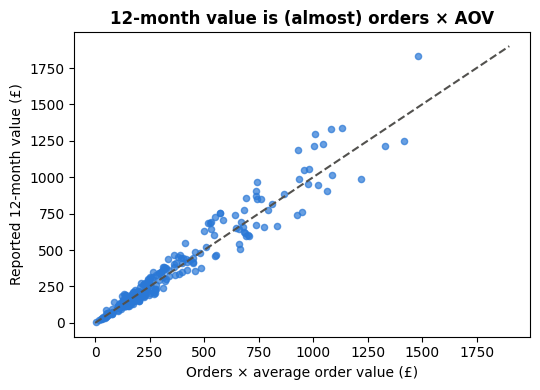

In [19]:
plt.figure(figsize=(5.5, 4))
plt.scatter(df["orders_x_aov"], df["customer_value_12m"], color=BLUE, alpha=0.7, s=20)
plt.plot([0, 1900], [0, 1900], color=GREY, linestyle="--")      # the "perfect match" line
plt.xlabel("Orders × average order value (£)")
plt.ylabel("Reported 12-month value (£)")
plt.title("12-month value is (almost) orders × AOV", fontweight="bold")
plt.tight_layout()
plt.savefig(FIG_FOLDER + "01_value_vs_orders_x_aov.png", dpi=200)
plt.show()

**Finding:** value is almost exactly orders × order value (r = 0.97). So "valuable customers place more orders" is true *by definition* —
it is not an insight. These two columns will be **left out of the driver model** in Step 3.

In [20]:
new_customers = df["tenure_months"] < 12
print("Customers with tenure under 12 months:", new_customers.sum(), "-> their '12-month' value is really a part-year value")

too_many_orders = new_customers & (df["total_orders"] > 2 * df["tenure_months"])
print("...of which have more than 2 orders per month of tenure:", too_many_orders.sum())

df.loc[too_many_orders, ["customer_id", "tenure_months", "total_orders", "customer_value_12m"]].sort_values("tenure_months")

Customers with tenure under 12 months: 51 -> their '12-month' value is really a part-year value
...of which have more than 2 orders per month of tenure: 16


,customer_id,tenure_months,total_orders,customer_value_12m
17,FG0018,1,7,156.29
18,FG0019,1,8,175.30
76,FG0077,1,3,213.83
100,FG0101,1,9,150.19
191,FG0192,1,6,160.44
211,FG0212,1,6,49.30
147,FG0148,1,13,186.58
111,FG0112,1,3,200.52
212,FG0213,1,4,449.11
229,FG0230,1,3,330.29


In [21]:
dq_log.append(["Definition / circularity", "total_orders, average_order_value", len(df),
               "value ≈ orders × AOV (r = 0.97)", "Exclude from driver model; use only to describe groups"])
dq_log.append(["Part-year value", "tenure_months", new_customers.sum(),
               "Tenure < 12 months, so 12-month value is not a full year", "Flag; sensitivity check without them"])
dq_log.append(["Logical inconsistency", "tenure_months vs total_orders", too_many_orders.sum(),
               "Tenure < 12 months but > 2 orders per month of tenure", "Flag; keep; sensitivity check"])

df = df.drop(columns="orders_x_aov")   # helper column no longer needed

## 4. How concentrated is customer value?

In [22]:
print("Mean value:  £", round(df["customer_value_12m"].mean(), 2))
print("Median value: £", round(df["customer_value_12m"].median(), 2))
print("Skewness:", round(df["customer_value_12m"].skew(), 2), "(above 1 = strongly skewed)")

Mean value:  £ 353.47
Median value: £ 228.91
Skewness: 1.65 (above 1 = strongly skewed)


In [23]:
# What share of revenue comes from the top 20% of customers?
threshold = df["customer_value_12m"].quantile(0.80)
top_customers = df[df["customer_value_12m"] >= threshold]

share_top20 = top_customers["customer_value_12m"].sum() / df["customer_value_12m"].sum()
print("Top-20% threshold: £", round(threshold, 2))
print("Top 20% of customers generate", round(share_top20 * 100, 1), "% of revenue")

Top-20% threshold: £ 600.35
Top 20% of customers generate 49.7 % of revenue


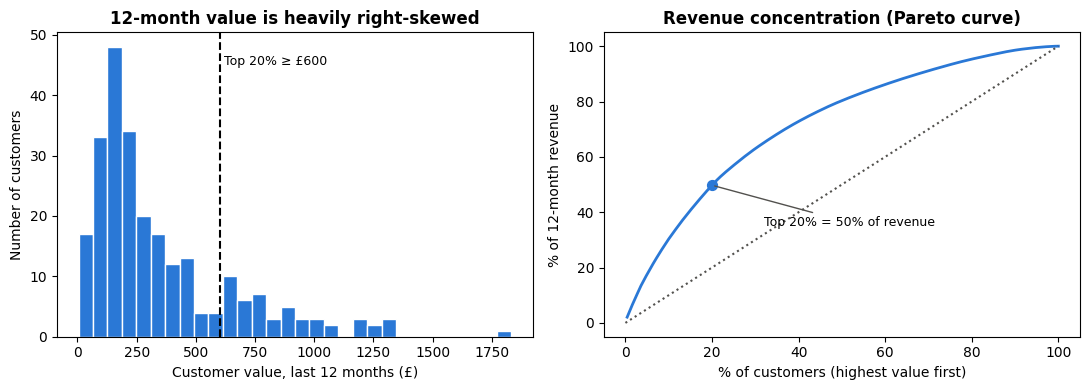

In [24]:
# Data for the Pareto curve: sort customers from highest to lowest value, then add up
values_sorted = df["customer_value_12m"].sort_values(ascending=False)
cum_revenue_pct  = values_sorted.cumsum() / values_sorted.sum() * 100
cum_customer_pct = np.arange(1, len(values_sorted) + 1) / len(values_sorted) * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

# Left: histogram of value
ax1.hist(df["customer_value_12m"], bins=30, color=BLUE, edgecolor="white")
ax1.axvline(threshold, color="black", linestyle="--")
ax1.text(threshold + 20, 45, f"Top 20% ≥ £{threshold:.0f}", fontsize=9)
ax1.set_title("12-month value is heavily right-skewed", fontweight="bold")
ax1.set_xlabel("Customer value, last 12 months (£)")
ax1.set_ylabel("Number of customers")

# Right: Pareto curve
ax2.plot(cum_customer_pct, cum_revenue_pct, color=BLUE, linewidth=2)
ax2.plot([0, 100], [0, 100], color=GREY, linestyle=":")          # line of perfect equality
ax2.scatter(20, share_top20 * 100, color=BLUE, s=50, zorder=3)
ax2.annotate(f"Top 20% = {share_top20:.0%} of revenue", (20, share_top20 * 100), xytext=(32, 35),
             arrowprops=dict(arrowstyle="-", color=GREY), fontsize=9)
ax2.set_title("Revenue concentration (Pareto curve)", fontweight="bold")
ax2.set_xlabel("% of customers (highest value first)")
ax2.set_ylabel("% of 12-month revenue")

plt.tight_layout()
plt.savefig(FIG_FOLDER + "01_value_distribution_pareto.png", dpi=200)
plt.show()

In [25]:
# Create the high-value flag for exploring (Step 2 creates the final version)
df["high_value"] = (df["customer_value_12m"] >= threshold).astype(int)
print("High-value customers:", df["high_value"].sum(), "out of", len(df))

High-value customers: 50 out of 250


## 5. What differs between high-value customers and the rest?

### 5.1 Correlation with value
We use **Spearman** correlation (based on ranks) instead of the usual Pearson correlation, because value is very skewed —
a handful of big spenders would otherwise dominate the result.

In [26]:
number_columns = ["age", "tenure_months", "distinct_product_types", "discount_sensitivity",
                  "email_engagement", "satisfaction_rating", "total_orders", "average_order_value"]

spearman = df[number_columns + ["customer_value_12m"]].corr(method="spearman")["customer_value_12m"]
spearman = spearman.drop("customer_value_12m").sort_values()
spearman.round(2)

discount_sensitivity     -0.18
satisfaction_rating       0.24
age                       0.24
average_order_value       0.36
distinct_product_types    0.39
email_engagement          0.58
tenure_months             0.58
total_orders              0.80
Name: customer_value_12m, dtype: float64

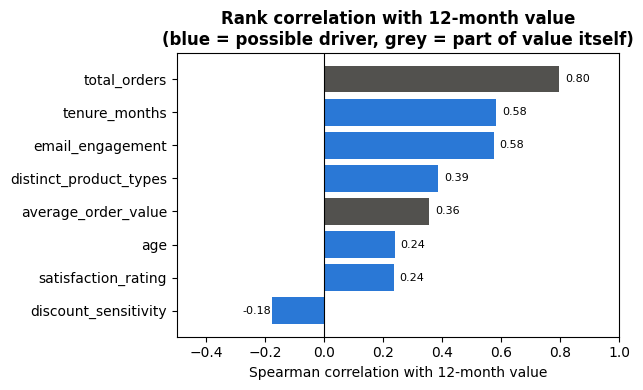

In [27]:
# Grey = parts of the value calculation (circular), blue = possible drivers
bar_colours = []
for column in spearman.index:
    if column in ["total_orders", "average_order_value"]:
        bar_colours.append(GREY)
    else:
        bar_colours.append(BLUE)

plt.figure(figsize=(6.5, 4))
plt.barh(spearman.index, spearman.values, color=bar_colours)
plt.axvline(0, color="black", linewidth=0.8)
for i, value in enumerate(spearman.values):
    plt.text(value + 0.02 if value >= 0 else value - 0.1, i, f"{value:.2f}", va="center", fontsize=8)
plt.xlim(-0.5, 1)
plt.xlabel("Spearman correlation with 12-month value")
plt.title("Rank correlation with 12-month value\n(blue = possible driver, grey = part of value itself)", fontweight="bold")
plt.tight_layout()
plt.savefig(FIG_FOLDER + "01_spearman_with_value.png", dpi=200)
plt.show()

### 5.2 High-value vs the rest — typical (median) values
The **Mann-Whitney test** checks whether the two groups really differ (p < 0.05 = a real difference, not chance).
It suits skewed data and small groups.

In [28]:
high = df[df["high_value"] == 1]
rest = df[df["high_value"] == 0]

profile = []
for column in number_columns:
    high_median = high[column].median()
    rest_median = rest[column].median()
    test_result = stats.mannwhitneyu(high[column].dropna(), rest[column].dropna())
    profile.append([column, high_median, rest_median, round(test_result.pvalue, 3)])

profile = pd.DataFrame(profile, columns=["variable", "high_value_median", "rest_median", "p_value"])
profile.to_csv(TAB_FOLDER + "01_profile_high_vs_rest.csv", index=False)
profile

,variable,high_value_median,rest_median,p_value
0,age,43.000,37.0000,0.021
1,tenure_months,39.000,20.0000,0.000
2,distinct_product_types,6.000,4.0000,0.000
3,discount_sensitivity,0.116,0.1525,0.077
4,email_engagement,77.200,44.1500,0.000
5,satisfaction_rating,4.500,4.3000,0.002
6,total_orders,21.000,8.0000,0.000
7,average_order_value,40.715,26.1400,0.000


### 5.3 High-value vs the rest — categories (subscription, channel, region)

In [29]:
# What % of each group's customers are high-value?
sub_rate     = df.groupby("subscription_status")["high_value"].mean().sort_values()
channel_rate = df.groupby("acquisition_channel")["high_value"].mean().sort_values()
region_rate  = df.groupby("region")["high_value"].mean().sort_values()

print((sub_rate * 100).round(0), "\n")
print((channel_rate * 100).round(0), "\n")
print((region_rate * 100).round(0))

subscription_status
no      3.0
yes    49.0
Name: high_value, dtype: float64 

acquisition_channel
Marketplace     0.0
Referral       19.0
Instagram      23.0
Google         33.0
Name: high_value, dtype: float64 

region
Scotland & Wales    12.0
Midlands            14.0
South East          21.0
North               21.0
South West          35.0
Name: high_value, dtype: float64


In [30]:
# Save one combined table
category_table = pd.concat([
    pd.DataFrame({"variable": "subscription_status", "group": sub_rate.index, "pct_high_value": sub_rate.values}),
    pd.DataFrame({"variable": "acquisition_channel", "group": channel_rate.index, "pct_high_value": channel_rate.values}),
    pd.DataFrame({"variable": "region", "group": region_rate.index, "pct_high_value": region_rate.values}),
])
category_table["pct_high_value"] = (category_table["pct_high_value"] * 100).round(1)
category_table.to_csv(TAB_FOLDER + "01_profile_high_vs_rest_categorical.csv", index=False)

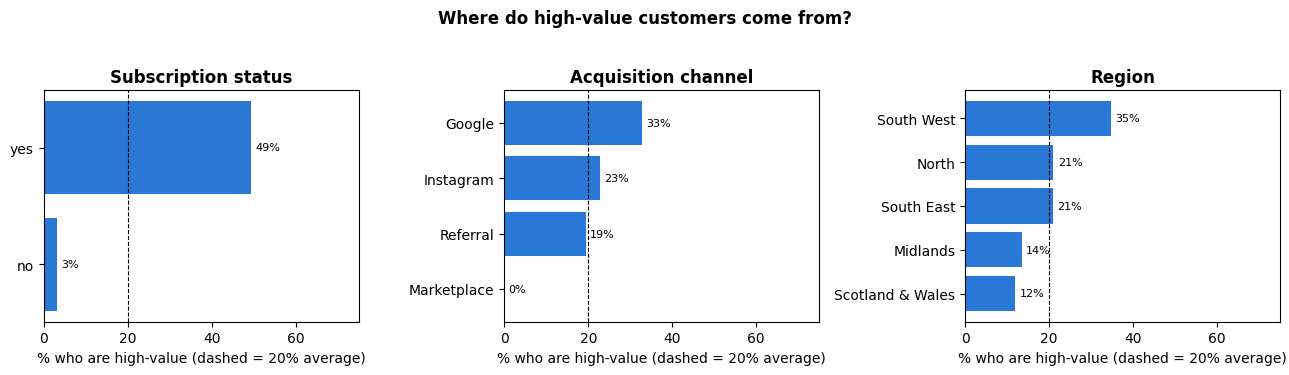

In [31]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
rates  = [sub_rate, channel_rate, region_rate]
titles = ["Subscription status", "Acquisition channel", "Region"]

for i in range(3):
    ax = axes[i]
    ax.barh(rates[i].index, rates[i].values * 100, color=BLUE)
    ax.axvline(20, color="black", linestyle="--", linewidth=0.8)      # overall average = 20%
    for j, value in enumerate(rates[i].values):
        ax.text(value * 100 + 1, j, f"{value:.0%}", va="center", fontsize=8)
    ax.set_title(titles[i], fontweight="bold")
    ax.set_xlabel("% who are high-value (dashed = 20% average)")
    ax.set_xlim(0, 75)

plt.suptitle("Where do high-value customers come from?", fontweight="bold", y=1.03)
plt.tight_layout()
plt.savefig(FIG_FOLDER + "01_high_value_rate_by_category.png", dpi=200, bbox_inches="tight")
plt.show()

### 5.4 Box plots — high-value vs the rest

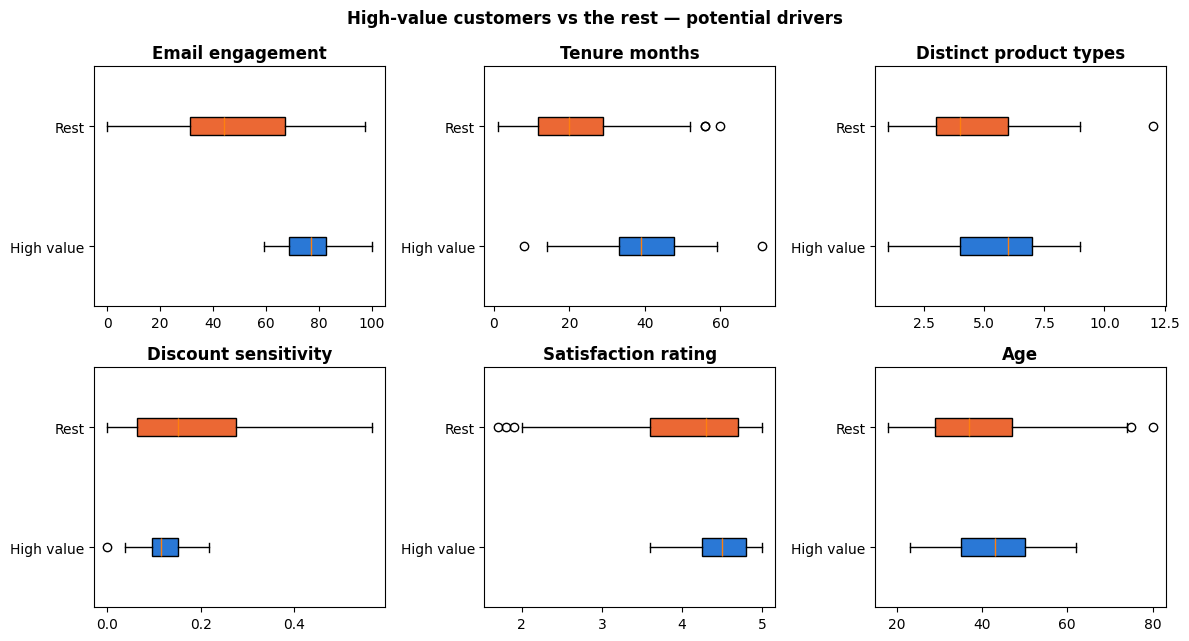

In [32]:
columns_to_plot = ["email_engagement", "tenure_months", "distinct_product_types",
                   "discount_sensitivity", "satisfaction_rating", "age"]

fig, axes = plt.subplots(2, 3, figsize=(12, 6.5))
axes = axes.flatten()      # turn the 2x3 grid into a simple list of 6 charts

for i in range(len(columns_to_plot)):
    column = columns_to_plot[i]
    data = [high[column].dropna(), rest[column].dropna()]
    box = axes[i].boxplot(data, vert=False, patch_artist=True, tick_labels=["High value", "Rest"])
    box["boxes"][0].set_facecolor(BLUE)
    box["boxes"][1].set_facecolor(ORANGE)
    axes[i].set_title(column.replace("_", " ").capitalize(), fontweight="bold")

plt.suptitle("High-value customers vs the rest — potential drivers", fontweight="bold")
plt.tight_layout()
plt.savefig(FIG_FOLDER + "01_boxplots_high_vs_rest.png", dpi=200)
plt.show()

## 6. Do the drivers overlap with each other?
If drivers move together (e.g. subscribers are also the most email-engaged), comparing them one at a time overstates each one.
This is why Step 3 uses a model that looks at all drivers **at the same time**.

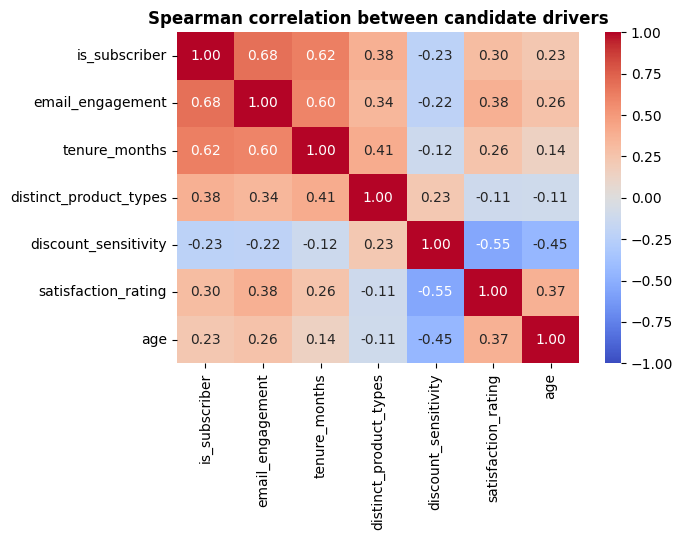

In [33]:
df["is_subscriber"] = (df["subscription_status"] == "yes").astype(int)

driver_columns = ["is_subscriber", "email_engagement", "tenure_months", "distinct_product_types",
                  "discount_sensitivity", "satisfaction_rating", "age"]
driver_corr = df[driver_columns].corr(method="spearman")

plt.figure(figsize=(7, 5.5))
sns.heatmap(driver_corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, center=0)
plt.title("Spearman correlation between candidate drivers", fontweight="bold")
plt.tight_layout()
plt.savefig(FIG_FOLDER + "01_driver_correlation_heatmap.png", dpi=200)
plt.show()

**Strongest overlaps:** subscription ↔ email engagement (0.68), subscription ↔ tenure (0.62), email ↔ tenure (0.60).
These three move together — the model in Step 3 will separate their effects.

## 7. Save the data-quality log (the to-do list for Step 2)

In [34]:
dq_table = pd.DataFrame(dq_log, columns=["issue", "column", "rows_affected", "evidence", "proposed_treatment"])
dq_table.to_csv(TAB_FOLDER + "01_data_quality_log.csv", index=False)
dq_table

,issue,column,rows_affected,evidence,proposed_treatment
0,Missing values,email_engagement,6,6/250 (2.4%); no clear pattern by subscription,Fill with subscription-group median + flag
1,Missing values (not at random),satisfaction_rating,8,8/250 (3.2%); 6 of 8 are subscribers (Fisher p...,Fill with subscription-group median + flag; do...
2,Suspicious value,average_order_value,2,Exactly £5.00 for 2 customers - looks like a f...,"Keep, flag"
3,Outlier,distinct_product_types,1,One customer = 12 types; all others 9 or fewer,Cap at 9 + flag
4,High-value outliers,customer_value_12m,19,Spend is skewed; these customers ARE the targe...,Keep - genuine
5,Definition / circularity,"total_orders, average_order_value",250,value ≈ orders × AOV (r = 0.97),Exclude from driver model; use only to describ...
6,Part-year value,tenure_months,51,"Tenure < 12 months, so 12-month value is not a...",Flag; sensitivity check without them
7,Logical inconsistency,tenure_months vs total_orders,16,Tenure < 12 months but > 2 orders per month of...,Flag; keep; sensitivity check


## 8. Summary for discussion

**Value is concentrated.** The top 20% of customers (≥ £600) generate **49.7%** of 12-month revenue (skew = 1.65).
This justifies a *high-value* flag at the top 20% and supports personalised (not uniform) marketing.

**What distinguishes high-value customers (one variable at a time):**
| Signal | High-value | Rest |
|---|---|---|
| Active subscription | **90%** | 23% |
| Acquired via Marketplace | **0%** | 30% |
| Acquired via Google | 50% | 26% |
| Median email engagement | 77 | 44 |
| Median tenure (months) | 39 | 20 |
| Median distinct tea types | 6 | 4 |
| Median discount sensitivity | 0.12 | 0.15 (weak, p = 0.08) |

**Caution:** subscription, email engagement and tenure overlap strongly (0.60–0.68), so Step 3 must use a multivariable model.

**Data-quality issues → Step 2:**
1. Missing `satisfaction_rating` (8) is **not random**: 75% are subscribers vs 35% overall (Fisher p = 0.03).
2. Missing `email_engagement` (6): no clear pattern.
3. `customer_value_12m` ≈ orders × AOV (r = 0.97) → orders and AOV are **excluded as drivers** (circular).
4. 51 customers (20%) have under 12 months' tenure (part-year value); 16 show more than 2 orders per month of tenure.
5. Minor: one product-type outlier (12), two order values of exactly £5.00.
6. No duplicates, no impossible values, clean categories.